# MNIST CNN — Complete Training Experiments & Report Outputs

Standalone continuation of `02_cnn_training.ipynb`. Runs six controlled configurations, saves best checkpoints, generates plots and tables, selects a model **using validation only**, evaluates the untouched test set once, and writes a report draft.

**Run from the project root or `notebooks/`**. All experiments are fresh runs, so their results may differ from the exploratory baseline (99.00% best validation accuracy) and Dropout (98.93%) previously observed. CPU execution may take a while.

## 1. Environment, paths and random seed

In [1]:
from pathlib import Path
import json, random, time, shutil, platform
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers
from sklearn.model_selection import train_test_split
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix, ConfusionMatrixDisplay
from IPython.display import display

SEED = 42
random.seed(SEED)
np.random.seed(SEED)
tf.keras.utils.set_random_seed(SEED)

cwd = Path.cwd()
ROOT = cwd if (cwd / "notebooks").is_dir() else cwd.parent if cwd.name == "notebooks" else None
if ROOT is None or not (ROOT / "notebooks").is_dir():
    raise RuntimeError("Run from project root or notebooks/ folder")
MODELS = ROOT / "results/models"
FIGS = ROOT / "results/figures"
METRICS = ROOT / "results/metrics"
REPORTS = ROOT / "reports"
for directory in (MODELS, FIGS, METRICS, REPORTS):
    directory.mkdir(parents=True, exist_ok=True)
print("Root:", ROOT, "| TF:", tf.__version__, "| Python:", platform.python_version())

Root: /Users/diegovertiz/Documents/AAAAAAAAAAdvanced_DS_VU/mnist-cnn-explainable-ai | TF: 2.21.0 | Python: 3.11.12


## 2. Load and preprocess MNIST — 50k train / 10k validation / 10k test

In [2]:
(x_full, y_full), (x_test_raw, y_test) = keras.datasets.mnist.load_data()
x_train_raw, x_val_raw, y_train, y_val = train_test_split(
    x_full, y_full, test_size=10_000, random_state=SEED, shuffle=True, stratify=y_full
)
def preprocess(x):
    return (x.astype("float32") / 255.0)[..., None]
x_train, x_val, x_test = map(preprocess, (x_train_raw, x_val_raw, x_test_raw))
assert x_train.shape == (50_000,28,28,1)
assert x_val.shape == (10_000,28,28,1)
assert x_test.shape == (10_000,28,28,1)
print("Train",x_train.shape,"Validation",x_val.shape,"Held-out test",x_test.shape)

Train (50000, 28, 28, 1) Validation (10000, 28, 28, 1) Held-out test (10000, 28, 28, 1)


## 3. Experiment design

All runs use two convolutional blocks (32 and 64 filters, 3×3, `same` padding, ReLU), 2×2 max pooling, a Dense head, softmax(10), Adam, sparse categorical cross-entropy and batch size 32.

**Questions:** (i) Does Dropout(0.3) improve validation generalization? (ii) Can 64 or 32 dense units achieve comparable performance with fewer parameters? (iii) How does the learning rate affect convergence?

All six models are trained from scratch under the same split, seed and early-stopping rule. This is an exploratory **single-seed** comparison, not a significance test. Test labels are never used for selection.

In [3]:
BATCH_SIZE = 32
MAX_EPOCHS = 15
PATIENCE = 3
EXPERIMENTS = [
    dict(name="baseline_128", dense_units=128, dropout=0.0, lr=0.001),
    dict(name="dropout_128", dense_units=128, dropout=0.3, lr=0.001),
    dict(name="dense_64", dense_units=64, dropout=0.0, lr=0.001),
    dict(name="dense_32", dense_units=32, dropout=0.0, lr=0.001),
    dict(name="dense_64_lr0001", dense_units=64, dropout=0.0, lr=0.0001),
    dict(name="dense_64_lr003", dense_units=64, dropout=0.0, lr=0.003),
]
display(pd.DataFrame(EXPERIMENTS))

,name,dense_units,dropout,lr
0,baseline_128,128,0.0,0.0010
1,dropout_128,128,0.3,0.0010
2,dense_64,64,0.0,0.0010
3,dense_32,32,0.0,0.0010
4,dense_64_lr0001,64,0.0,0.0001
5,dense_64_lr003,64,0.0,0.0030


## 4. Architecture and reusable training function

In [4]:
def build_model(dense_units, dropout):
    network = [
        keras.Input(shape=(28,28,1)),
        layers.Conv2D(32, (3,3), padding="same", activation="relu"),
        layers.MaxPooling2D((2,2)),
        layers.Conv2D(64, (3,3), padding="same", activation="relu"),
        layers.MaxPooling2D((2,2)),
        layers.Flatten(),
        layers.Dense(dense_units, activation="relu"),
    ]
    if dropout > 0:
        network.append(layers.Dropout(dropout))
    network.append(layers.Dense(10, activation="softmax"))
    return keras.Sequential(network)

def save_curves(history, name):
    epochs = range(1, len(history["loss"]) + 1)
    for key, label in (("loss", "Cross-Entropy Loss"), ("accuracy", "Accuracy")):
        fig, ax = plt.subplots(figsize=(8,5))
        ax.plot(epochs, history[key], marker="o", label="Training")
        ax.plot(epochs, history["val_"+key], marker="o", label="Validation")
        ax.set(title=f"{name}: {label}", xlabel="Epoch", ylabel=label)
        ax.set_xticks(list(epochs))
        ax.grid(alpha=0.3)
        ax.legend()
        fig.tight_layout()
        fig.savefig(FIGS / f"{name}_{key}.png", dpi=180)
        plt.close(fig)

def train_one(config):
    name = config["name"]
    print("\nRUNNING:", name)
    keras.backend.clear_session()
    tf.keras.utils.set_random_seed(SEED)
    model = build_model(config["dense_units"], config["dropout"])
    model.compile(optimizer=keras.optimizers.Adam(learning_rate=config["lr"]),
                  loss="sparse_categorical_crossentropy", metrics=["accuracy"])
    checkpoint = MODELS / f"{name}.keras"
    callbacks = [
        keras.callbacks.ModelCheckpoint(str(checkpoint), monitor="val_loss", mode="min", save_best_only=True),
        keras.callbacks.EarlyStopping(monitor="val_loss", mode="min", patience=PATIENCE, restore_best_weights=True),
    ]
    start = time.perf_counter()
    history = model.fit(x_train, y_train, validation_data=(x_val,y_val),
                        batch_size=BATCH_SIZE, epochs=MAX_EPOCHS, callbacks=callbacks, verbose=2)
    elapsed = time.perf_counter() - start
    h = {k:[float(v) for v in vals] for k, vals in history.history.items()}
    best_idx = int(np.argmin(h["val_loss"]))
    saved = keras.models.load_model(checkpoint)
    saved_loss, saved_acc = saved.evaluate(x_val,y_val,verbose=0)
    assert np.isclose(saved_loss, h["val_loss"][best_idx], atol=1e-5)
    assert np.isclose(saved_acc, h["val_accuracy"][best_idx], atol=1e-5)
    (METRICS / f"{name}_history.json").write_text(json.dumps(h,indent=2))
    save_curves(h, name)
    return dict(**config, params=saved.count_params(), epochs_run=len(h["loss"]),
                best_epoch=best_idx+1, val_loss=saved_loss, val_accuracy=saved_acc,
                seconds=round(elapsed,1), checkpoint=str(checkpoint.relative_to(ROOT)))

## 5. Run six configurations

**This cell takes the longest.** Execute once; it saves the best checkpoint and curves for every configuration. Do not use the held-out test set to choose a model.

In [5]:
rows = [train_one(config) for config in EXPERIMENTS]
comparison = pd.DataFrame(rows).sort_values(["val_loss","params"]).reset_index(drop=True)
comparison.to_csv(METRICS / "cnn_experiments.csv", index=False)
display(comparison)


RUNNING: baseline_128
Epoch 1/15
1563/1563 - 31s - 20ms/step - accuracy: 0.9593 - loss: 0.1357 - val_accuracy: 0.9832 - val_loss: 0.0562
Epoch 2/15
1563/1563 - 26s - 17ms/step - accuracy: 0.9862 - loss: 0.0436 - val_accuracy: 0.9849 - val_loss: 0.0548
Epoch 3/15
1563/1563 - 26s - 16ms/step - accuracy: 0.9909 - loss: 0.0282 - val_accuracy: 0.9816 - val_loss: 0.0641
Epoch 4/15
1563/1563 - 27s - 17ms/step - accuracy: 0.9938 - loss: 0.0195 - val_accuracy: 0.9842 - val_loss: 0.0588
Epoch 5/15
1563/1563 - 29s - 18ms/step - accuracy: 0.9946 - loss: 0.0160 - val_accuracy: 0.9867 - val_loss: 0.0631

RUNNING: dropout_128
Epoch 1/15
1563/1563 - 27s - 17ms/step - accuracy: 0.9484 - loss: 0.1674 - val_accuracy: 0.9849 - val_loss: 0.0543
Epoch 2/15
1563/1563 - 26s - 16ms/step - accuracy: 0.9824 - loss: 0.0577 - val_accuracy: 0.9859 - val_loss: 0.0469
Epoch 3/15
1563/1563 - 35s - 22ms/step - accuracy: 0.9867 - loss: 0.0410 - val_accuracy: 0.9874 - val_loss: 0.0438
Epoch 4/15
1563/1563 - 28s - 18ms/s

,name,dense_units,dropout,lr,params,epochs_run,best_epoch,val_loss,val_accuracy,seconds,checkpoint
0,dropout_128,128,0.3,0.0010,421642,6,3,0.043821,0.9874,169.5,results/models/dropout_128.keras
1,dense_64,64,0.0,0.0010,220234,5,2,0.047287,0.9867,104.9,results/models/dense_64.keras
2,dense_32,32,0.0,0.0010,119530,9,6,0.047629,0.9876,173.4,results/models/dense_32.keras
3,dense_64_lr0001,64,0.0,0.0001,220234,15,14,0.050212,0.9856,317.5,results/models/dense_64_lr0001.keras
4,baseline_128,128,0.0,0.0010,421642,5,2,0.054798,0.9849,138.0,results/models/baseline_128.keras
5,dense_64_lr003,64,0.0,0.0030,220234,10,7,0.058687,0.9884,217.6,results/models/dense_64_lr003.keras


## 6. Comparative figures

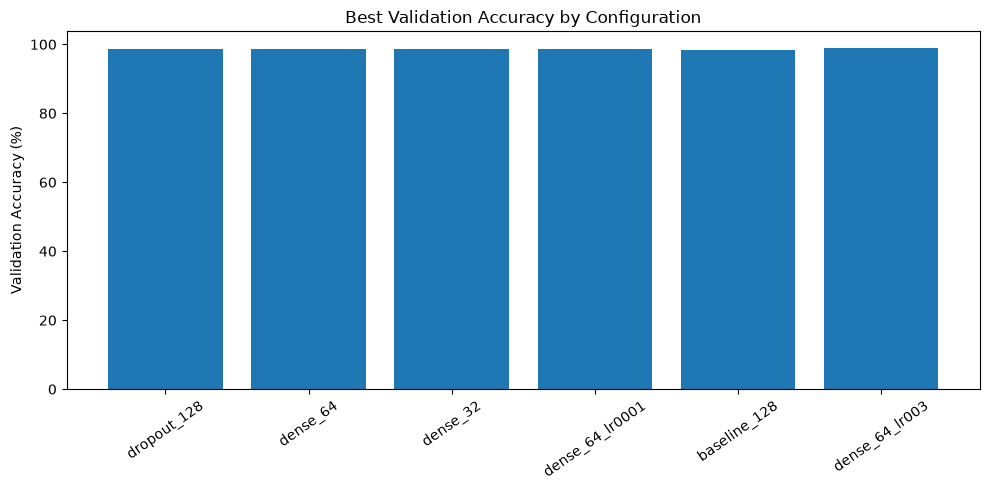

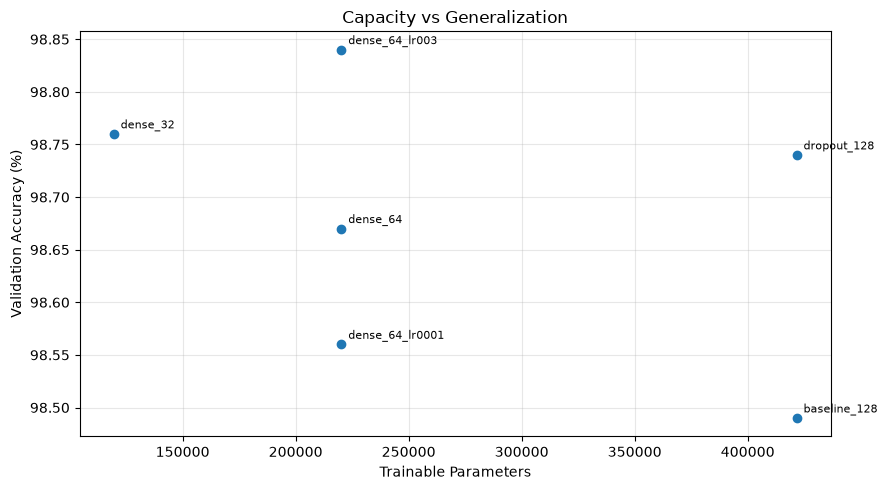

In [6]:
fig, ax = plt.subplots(figsize=(10,5))
ax.bar(comparison["name"], comparison["val_accuracy"]*100)
ax.set(title="Best Validation Accuracy by Configuration",ylabel="Validation Accuracy (%)")
ax.tick_params(axis="x",rotation=35)
fig.tight_layout()
fig.savefig(FIGS / "comparison_validation_accuracy.png",dpi=180)
plt.show()

fig, ax = plt.subplots(figsize=(9,5))
ax.scatter(comparison["params"],comparison["val_accuracy"]*100)
for row in comparison.itertuples():
    ax.annotate(row.name,(row.params,row.val_accuracy*100),xytext=(5,4),textcoords="offset points",fontsize=8)
ax.set(xlabel="Trainable Parameters",ylabel="Validation Accuracy (%)",title="Capacity vs Generalization")
ax.grid(alpha=0.3)
fig.tight_layout()
fig.savefig(FIGS / "comparison_capacity.png",dpi=180)
plt.show()

## 7. Select model using validation loss

Selection criterion: lowest validation loss, breaking exact ties with parameter count. A stable `.keras` filename is created for the teammate working on XAI.

In [7]:
winner = comparison.iloc[0]
selected_name = str(winner["name"])
selected_path = MODELS / "cnn_selected_for_xai.keras"
shutil.copy2(ROOT / winner["checkpoint"], selected_path)
selected_model = keras.models.load_model(selected_path)
selection = dict(selected_model=selected_name, checkpoint=str(selected_path.relative_to(ROOT)),
                 best_epoch=int(winner["best_epoch"]), val_loss=float(winner["val_loss"]),
                 val_accuracy=float(winner["val_accuracy"]),
                 input_shape=[28,28,1], preprocessing="float32 / 255.0", classes=list(range(10)))
(METRICS / "cnn_selection.json").write_text(json.dumps(selection,indent=2))
print(json.dumps(selection,indent=2))

{
  "selected_model": "dropout_128",
  "checkpoint": "results/models/cnn_selected_for_xai.keras",
  "best_epoch": 3,
  "val_loss": 0.043821316212415695,
  "val_accuracy": 0.9873999953269958,
  "input_shape": [
    28,
    28,
    1
  ],
  "preprocessing": "float32 / 255.0",
  "classes": [
    0,
    1,
    2,
    3,
    4,
    5,
    6,
    7,
    8,
    9
  ]
}


## 8. Final held-out test evaluation — once, after selection

The test set is evaluated **only after** selecting the model using validation. Do not revise hyperparameters based on test performance; doing so invalidates the held-out evaluation.

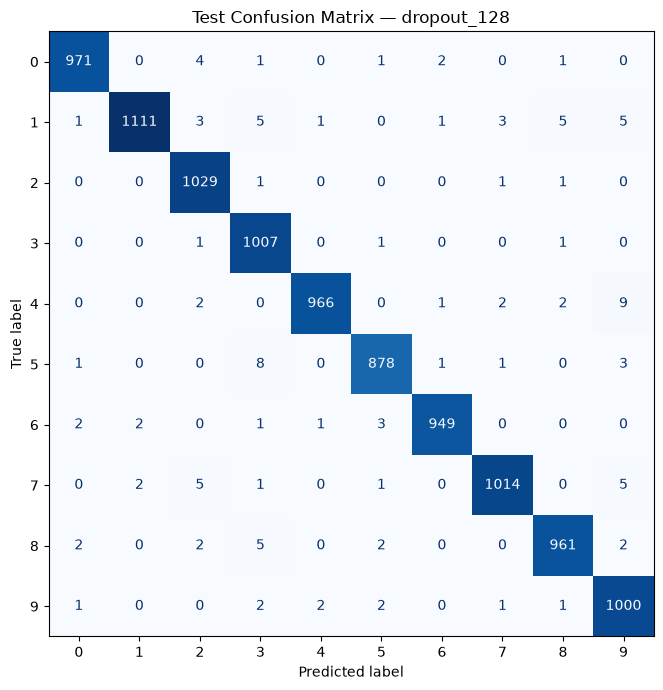

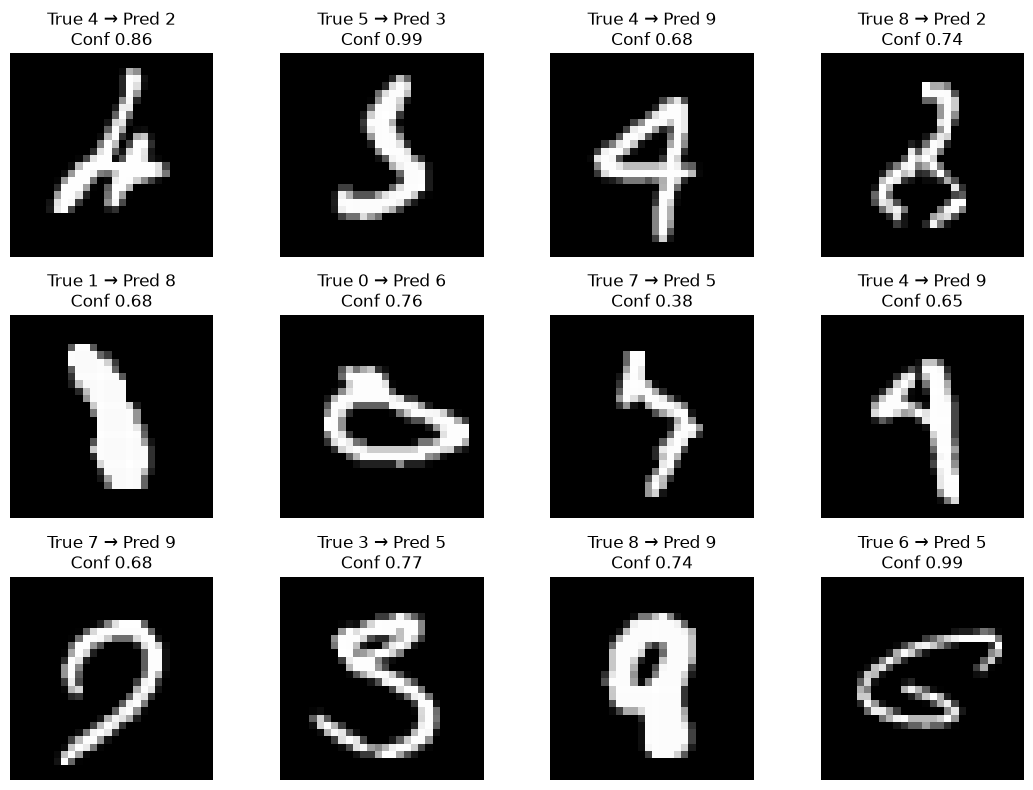

{
  "selected_model": "dropout_128",
  "test_accuracy": 0.9886000156402588,
  "test_loss": 0.03368433192372322,
  "macro_f1": 0.9886182412680771,
  "errors": 114,
  "test_n": 10000
}


In [8]:
test_loss, test_accuracy = selected_model.evaluate(x_test,y_test,verbose=0)
probabilities = selected_model.predict(x_test,batch_size=256,verbose=0)
y_pred = probabilities.argmax(axis=1)
assert np.isclose(test_accuracy,accuracy_score(y_test,y_pred),atol=1e-6)
report = classification_report(y_test,y_pred,labels=list(range(10)),output_dict=True,zero_division=0)
pd.DataFrame(report).T.to_csv(METRICS / "test_classification_report.csv")
cm = confusion_matrix(y_test,y_pred,labels=list(range(10)))
pd.DataFrame(cm,index=range(10),columns=range(10)).to_csv(METRICS / "test_confusion_matrix.csv")
fig, ax = plt.subplots(figsize=(8,7))
ConfusionMatrixDisplay(cm,display_labels=list(range(10))).plot(ax=ax,cmap="Blues",values_format="d",colorbar=False)
ax.set_title(f"Test Confusion Matrix — {selected_name}")
fig.tight_layout()
fig.savefig(FIGS / "test_confusion_matrix.png",dpi=180)
plt.show()
errors = np.flatnonzero(y_pred != y_test)
fig, axes = plt.subplots(3,4,figsize=(11,8))
for ax in axes.flat:
    ax.axis("off")
for ax, idx in zip(axes.flat,errors[:12]):
    ax.imshow(x_test[idx,:,:,0],cmap="gray")
    ax.set_title(f"True {y_test[idx]} → Pred {y_pred[idx]}\nConf {probabilities[idx,y_pred[idx]]:.2f}")
    ax.axis("off")
fig.tight_layout()
fig.savefig(FIGS / "test_misclassifications.png",dpi=180)
plt.show()
metrics = dict(selected_model=selected_name,test_accuracy=float(test_accuracy),test_loss=float(test_loss),
               macro_f1=float(report["macro avg"]["f1-score"]),errors=int(len(errors)),test_n=int(len(y_test)))
(METRICS / "test_metrics.json").write_text(json.dumps(metrics,indent=2))
print(json.dumps(metrics,indent=2))

## 9. Export report-ready draft and top confusions

In [9]:
confusions = sorted([{"true":i,"predicted":j,"count":int(cm[i,j])}
                     for i in range(10) for j in range(10) if i!=j and cm[i,j]>0],
                    key=lambda item:item["count"],reverse=True)
pd.DataFrame(confusions).to_csv(METRICS / "top_confusions.csv",index=False)
display(pd.DataFrame(confusions).head(10))

lines = [
    "# CNN Architecture & Training — Report Draft",
    "",
    "## Architecture",
    "All configurations use Conv2D(32, 3×3, same, ReLU), MaxPooling2D(2×2), Conv2D(64, 3×3, same, ReLU), MaxPooling2D(2×2), Flatten, a variable-size Dense(ReLU) head, and Dense(10, softmax). The regularization experiment adds Dropout(0.3) before the output.",
    "",
    "## Dataset and methodology",
    "The original MNIST training split (60,000 images) was stratified into 50,000 training and 10,000 validation images with random_state=42. The official 10,000-image test set was held out. Images were scaled to [0,1] as float32 and reshaped to 28×28×1.",
    f"All models used Adam, sparse categorical cross-entropy, batch size {BATCH_SIZE}, and up to {MAX_EPOCHS} epochs with early stopping (patience {PATIENCE}) and best-val-loss checkpoints.",
    "",
    "## Validation comparison",
    "| Configuration | Dense | Dropout | LR | Parameters | Best epoch | Val accuracy | Val loss | Time (s) |",
    "|---|---:|---:|---:|---:|---:|---:|---:|---:|",
]
for row in comparison.itertuples():
    lines.append(f"| {row.name} | {row.dense_units} | {row.dropout:g} | {row.lr:g} | {row.params:,} | {row.best_epoch} | {row.val_accuracy:.2%} | {row.val_loss:.4f} | {row.seconds:.1f} |")
lines += ["", "## Selected model and test results",
          f"The model **{selected_name}** was selected using minimum validation loss ({winner['val_loss']:.4f}, accuracy {winner['val_accuracy']:.2%}). On the untouched test set, accuracy was **{test_accuracy:.2%}**, loss **{test_loss:.4f}**, macro-F1 **{metrics['macro_f1']:.4f}**, with {len(errors)} errors out of {len(y_test):,} images.",
          "", "## Error analysis", "Use `results/figures/test_confusion_matrix.png` and `test_misclassifications.png` to discuss recurring digit confusions and difficult handwriting. Coordinate saliency/Grad-CAM interpretation with the XAI teammate.",
          "", "## Limitations", "Single-seed comparisons cannot establish statistical significance. Future work: repeated seeds, data augmentation, robustness tests and probability calibration. Do not tune against the test set.",
          "", "## Figures", "- `results/figures/comparison_validation_accuracy.png`", "- `results/figures/comparison_capacity.png`", "- `results/figures/test_confusion_matrix.png`", "- `results/figures/test_misclassifications.png`", "- Per-experiment training curves in `results/figures/`."]
report_file = REPORTS / "cnn_training_results_draft.md"
report_file.write_text("\n".join(lines)+"\n",encoding="utf-8")
print("Report draft:",report_file)

,true,predicted,count
0,4,9,9
1,5,3,8
2,1,3,5
3,1,8,5
4,1,9,5
5,7,2,5
6,7,9,5
7,8,3,5
8,0,2,4
9,1,2,3


Report draft: /Users/diegovertiz/Documents/AAAAAAAAAAdvanced_DS_VU/mnist-cnn-explainable-ai/reports/cnn_training_results_draft.md


## 10. XAI handoff

- Model: `results/models/cnn_selected_for_xai.keras`
- Input: `(N, 28, 28, 1)`, float32 pixels divided by 255
- Output: 10 softmax probabilities, digits `0` to `9`
- `results/metrics/cnn_selection.json` records model choice.

**Note:** XAI implementation should use the selected checkpoint; do not retrain a different architecture without coordinating.

In [10]:
xai_model = keras.models.load_model(MODELS / "cnn_selected_for_xai.keras")
example_prediction = xai_model.predict(x_val[:1],verbose=0)
print("Prediction:",int(np.argmax(example_prediction[0])))

Prediction: 7


## 11. GitHub checklist

Save the notebook, then from the repository root:

```bash
git status
git add notebooks/03_cnn_experiments_and_reporting.ipynb reports/cnn_training_results_draft.md
git add results/metrics/ results/figures/
git add -f results/models/cnn_selected_for_xai.keras
git commit -m "feat: CNN hyperparameter experiments and XAI model handoff"
git push
```

**Your `.gitignore` excludes `.keras` files**, so `git add -f` is necessary for the selected model. The other six checkpoints can remain local to keep the repository smaller. If your prior PR has been merged, create a **new branch from updated `main`** before making the commit, then open another PR. Ensure teammates can run the notebook with the project's dependencies.